# Лабораторная работа №3
## Продвинутые модели машинного обучения и интерпретация

**Вариант:** 10  
**Датасет:** Iris  
**Задача:** многоклассовая классификация  
**Модели:** XGBoost, LightGBM, CatBoost, стекинг  
**Оптимизация:** Optuna, 50 trials  
**Интерпретация:** SHAP

## 1. Окружение и воспроизводимость

In [1]:
from pathlib import Path
import json
import platform
import subprocess
import sys
import time
import warnings

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from catboost import CatBoostClassifier
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / ".git").exists():
    raise RuntimeError("Запустите Notebook из корня репозитория или папки notebooks.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "lab3"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "lab3"
FIGURE_DIR = REPORT_DIR / "figures"
for directory in (RAW_DIR, PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

branch = subprocess.run(["git", "branch", "--show-current"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True).stdout.strip()
print(f"Корень проекта: {PROJECT_ROOT}")
print(f"Ветка: {branch}")
print(f"Python: {platform.python_version()}")

C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Корень проекта: C:\Users\Доктор Варвар\Desktop\все\MWwithD
Ветка: fix/all-labs-requirements
Python: 3.11.9


## 2. Загрузка и подготовка Iris

Данные делятся на train/test до сравнения моделей. Test не используется ни в
кросс-валидации, ни в Optuna, ни при выборе между бустингом и стекингом.

In [2]:
iris = load_iris(as_frame=True)
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = iris.data.copy()
df.columns = features
df["target"] = iris.target.astype(int)

X = df[features]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

raw_path = RAW_DIR / "iris_lab3.csv"
train_path = PROCESSED_DIR / "train.csv"
test_path = PROCESSED_DIR / "test.csv"
df.to_csv(raw_path, index=False)
train_df = X_train.copy(); train_df["target"] = y_train
test_df = X_test.copy(); test_df["target"] = y_test
train_df.to_csv(train_path, index=False); test_df.to_csv(test_path, index=False)

print(f"Исходные данные: {df.shape}")
print(f"Train: {train_df.shape}; test: {test_df.shape}")
display(df.head())
display(df.describe().T)
display(df["target"].value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))
assert not df.isna().any().any()

Исходные данные: (150, 5)
Train: (120, 5); test: (30, 5)


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 3. Исследовательский анализ

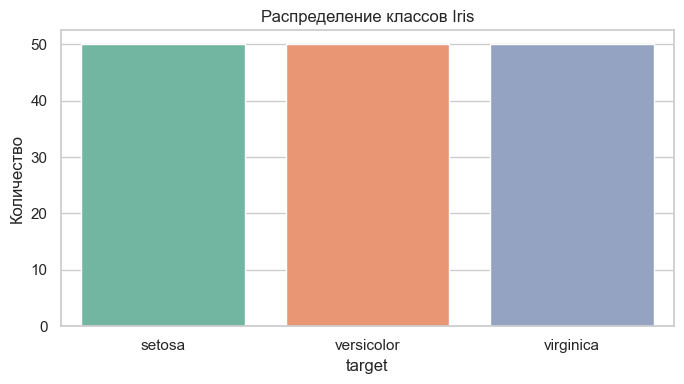

Сохранено: reports\lab3\figures\class_distribution.png


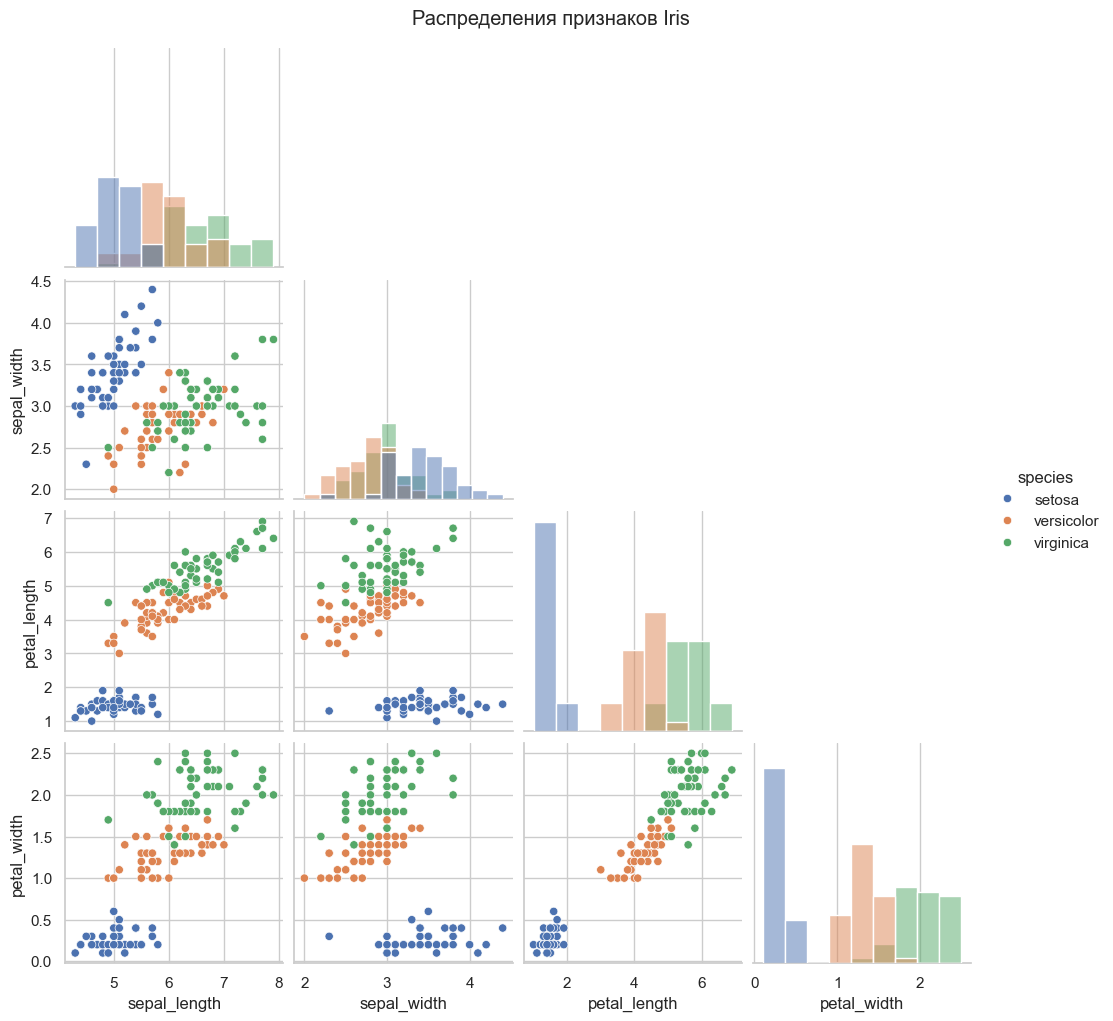

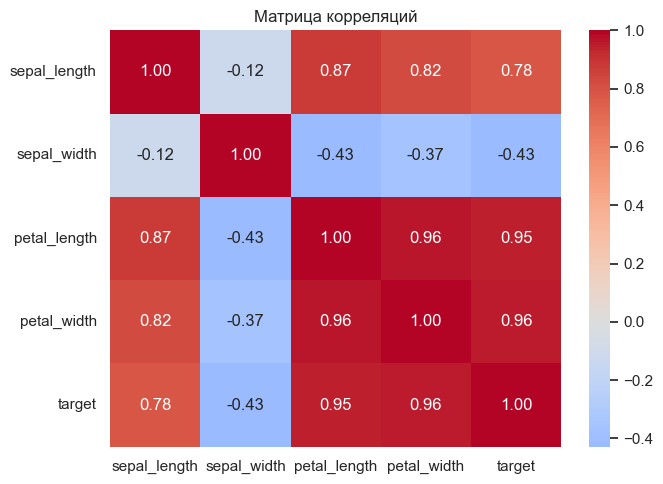

Сохранено: reports\lab3\figures\correlation_matrix.png


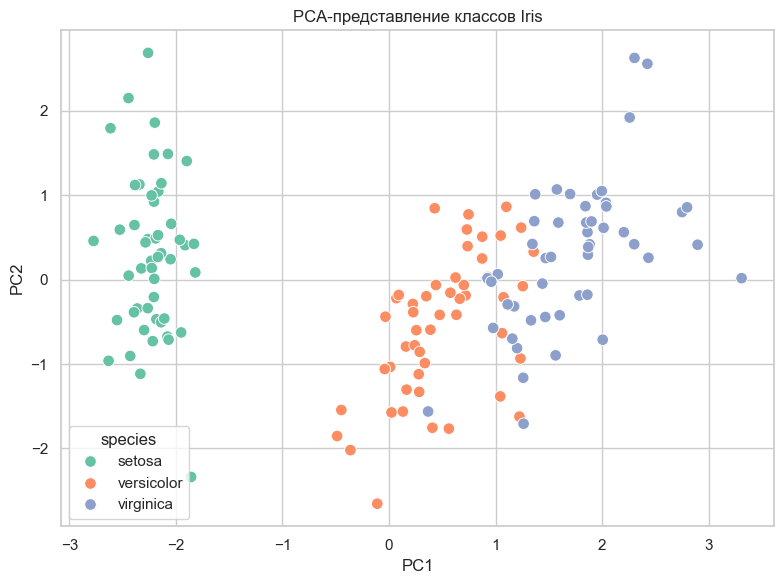

Сохранено: reports\lab3\figures\pca_classes.png


In [3]:
def save_figure(name):
    path = FIGURE_DIR / name
    plt.tight_layout(); plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show(); plt.close()
    print(f"Сохранено: {path.relative_to(PROJECT_ROOT)}")

plt.figure(figsize=(7, 4))
species = df["target"].map(dict(enumerate(iris.target_names)))
sns.countplot(x=species, hue=species, palette="Set2", legend=False)
plt.title("Распределение классов Iris"); plt.ylabel("Количество")
save_figure("class_distribution.png")

plot_df = df.copy()
plot_df["species"] = species
pair = sns.pairplot(plot_df, vars=features, hue="species", corner=True, diag_kind="hist")
pair.figure.suptitle("Распределения признаков Iris", y=1.02)
pair.figure.savefig(FIGURE_DIR / "feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(pair.figure)

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций")
save_figure("correlation_matrix.png")

scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(scaled)
pca_df = pd.DataFrame({"PC1": pca[:, 0], "PC2": pca[:, 1], "species": species})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="species", palette="Set2", s=70)
plt.title("PCA-представление классов Iris")
save_figure("pca_classes.png")

## 4. Сравнение XGBoost, LightGBM и CatBoost

Все модели оцениваются на одних и тех же пяти стратифицированных фолдах.
Модельные гиперпараметры оставлены библиотечными по умолчанию; явно заданы
только seed, число потоков и параметры вывода для воспроизводимости.
Помимо метрик фиксируется время обучения и предсказания.

,model,roc_auc_mean,roc_auc_std,accuracy_mean,f1_macro_mean,fit_time_mean,score_time_mean
2,CatBoost,0.998958,0.002083,0.958333,0.957971,0.784879,0.006784
1,LightGBM,0.987500,0.016667,0.958333,0.957971,0.013867,0.006386
0,XGBoost,0.984375,0.024206,0.950000,0.949637,1.742466,0.006908


Выбранная библиотека для Optuna: CatBoost


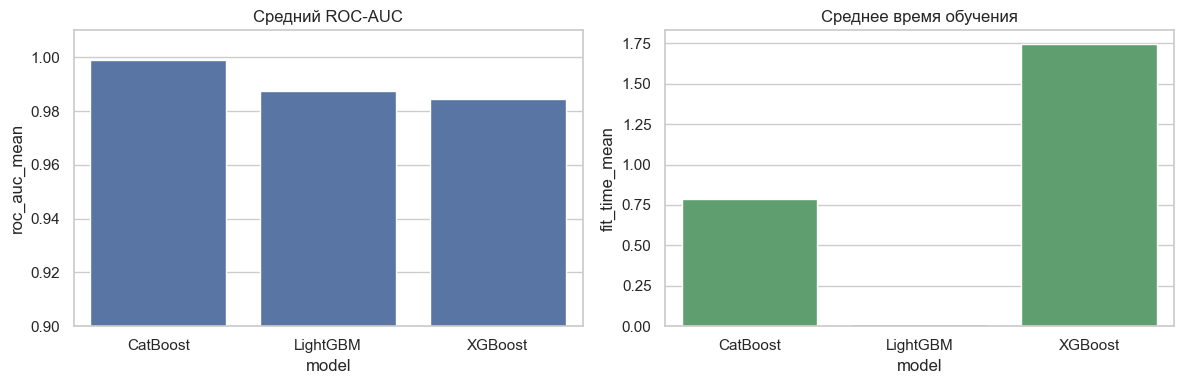

Сохранено: reports\lab3\figures\boosting_comparison.png


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc_ovr", "accuracy": "accuracy", "f1": "f1_macro"}

baseline_models = {
    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE, n_jobs=1,
        eval_metric="mlogloss", verbosity=0),
    "LightGBM": LGBMClassifier(
        random_state=RANDOM_STATE, n_jobs=1, verbosity=-1),
    "CatBoost": CatBoostClassifier(
        random_seed=RANDOM_STATE, verbose=False,
        allow_writing_files=False, thread_count=1),
}

boosting_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=-1, return_train_score=False)
    boosting_rows.append({
        "model": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "accuracy_mean": scores["test_accuracy"].mean(),
        "f1_macro_mean": scores["test_f1"].mean(),
        "fit_time_mean": scores["fit_time"].mean(),
        "score_time_mean": scores["score_time"].mean(),
    })

boosting_results = pd.DataFrame(boosting_rows).sort_values(
    ["roc_auc_mean", "f1_macro_mean", "fit_time_mean"],
    ascending=[False, False, True])
boosting_results.to_csv(REPORT_DIR / "boosting_comparison.csv", index=False)
display(boosting_results)
best_library = boosting_results.iloc[0]["model"]
print(f"Выбранная библиотека для Optuna: {best_library}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=boosting_results, x="model", y="roc_auc_mean", ax=axes[0], color="#4C72B0")
axes[0].set_ylim(0.90, 1.01); axes[0].set_title("Средний ROC-AUC")
sns.barplot(data=boosting_results, x="model", y="fit_time_mean", ax=axes[1], color="#55A868")
axes[1].set_title("Среднее время обучения")
save_figure("boosting_comparison.png")

## 5. Оптимизация лучшей библиотеки через Optuna

Выполняется 50 trials. Каждый trial оценивается пятифолдовой CV только на
train. Пространство ограничено с учётом малого размера Iris.

Лучший trial: 2
Лучшая CV ROC-AUC: 1.0000
Параметры: {'iterations': 54, 'depth': 6, 'learning_rate': 0.16967533607196555, 'l2_leaf_reg': 0.0070689749506246055, 'random_strength': 0.36364993441420124}


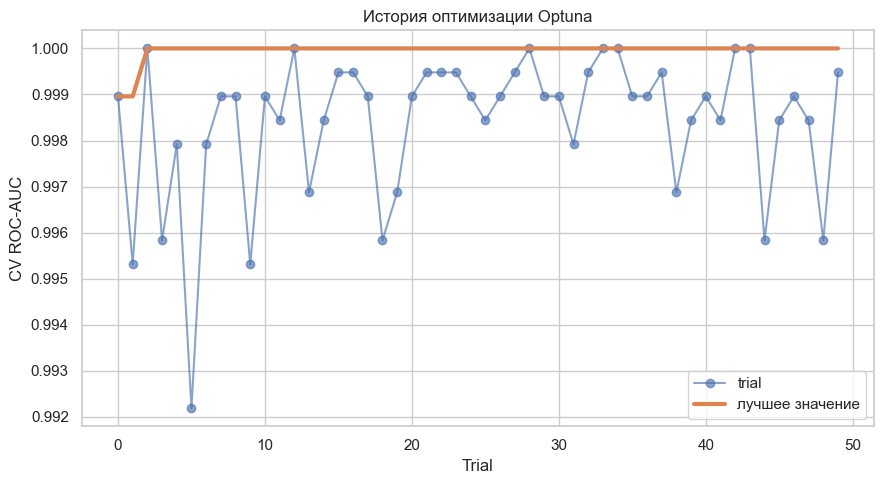

Сохранено: reports\lab3\figures\optuna_history.png


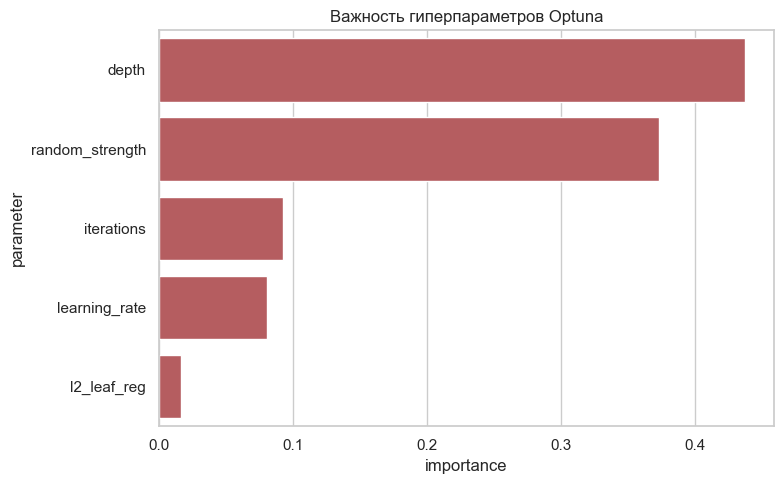

Сохранено: reports\lab3\figures\optuna_param_importance.png


In [5]:
def create_optimized_model(model_name, params):
    if model_name == "XGBoost":
        return XGBClassifier(
            **params, random_state=RANDOM_STATE, n_jobs=1,
            eval_metric="mlogloss", verbosity=0)
    if model_name == "LightGBM":
        return LGBMClassifier(
            **params, random_state=RANDOM_STATE, n_jobs=1, verbosity=-1)
    return CatBoostClassifier(
        **params, random_seed=RANDOM_STATE, verbose=False,
        allow_writing_files=False, thread_count=1)

def objective(trial):
    if best_library == "XGBoost":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 250),
            "max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        }
    elif best_library == "LightGBM":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 250),
            "max_depth": trial.suggest_int("max_depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 4, 31),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        }
    else:
        params = {
            "iterations": trial.suggest_int("iterations", 50, 250),
            "depth": trial.suggest_int("depth", 2, 6),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-3, 10.0, log=True),
            "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        }
    model = create_optimized_model(best_library, params)
    return cross_val_score(model, X_train, y_train, cv=cv,
                           scoring="roc_auc_ovr", n_jobs=-1).mean()

sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction="maximize", sampler=sampler,
                            study_name="iris_variant10_boosting")
study.optimize(objective, n_trials=50, show_progress_bar=False)

optuna_trials = study.trials_dataframe()
optuna_trials.to_csv(REPORT_DIR / "optuna_trials.csv", index=False)
(REPORT_DIR / "best_optuna_params.json").write_text(
    json.dumps(study.best_params, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Лучший trial: {study.best_trial.number}")
print(f"Лучшая CV ROC-AUC: {study.best_value:.4f}")
print(f"Параметры: {study.best_params}")

plt.figure(figsize=(9, 5))
plt.plot(optuna_trials["number"], optuna_trials["value"], "o-", alpha=0.65, label="trial")
plt.plot(optuna_trials["number"], optuna_trials["value"].cummax(), linewidth=3,
         label="лучшее значение")
plt.xlabel("Trial"); plt.ylabel("CV ROC-AUC"); plt.title("История оптимизации Optuna")
plt.legend(); save_figure("optuna_history.png")

param_importance = optuna.importance.get_param_importances(study)
importance_df = pd.DataFrame({"parameter": param_importance.keys(),
                              "importance": param_importance.values()})
importance_df.to_csv(REPORT_DIR / "optuna_param_importance.csv", index=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, y="parameter", x="importance", color="#C44E52")
plt.title("Важность гиперпараметров Optuna")
save_figure("optuna_param_importance.png")

optimized_model = create_optimized_model(best_library, study.best_params)
optimized_model.fit(X_train, y_train)

## 6. Интерпретация оптимизированной модели через SHAP

Для мультикласса подробно анализируется класс virginica (индекс 2). Строятся
summary, bar, два dependence plot и waterfall для тестового объекта.

,feature,mean_abs_shap
2,petal_length,1.884474
3,petal_width,1.615840
0,sepal_length,0.430099
1,sepal_width,0.178027


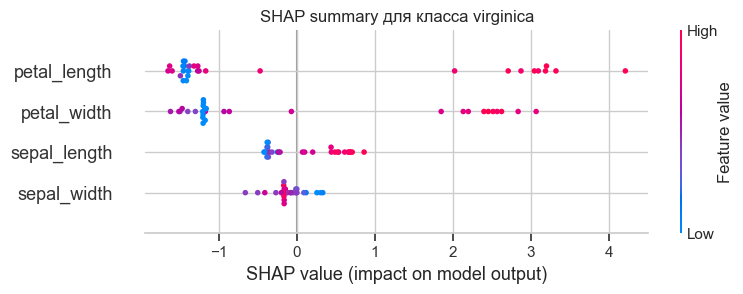

Сохранено: reports\lab3\figures\shap_summary.png


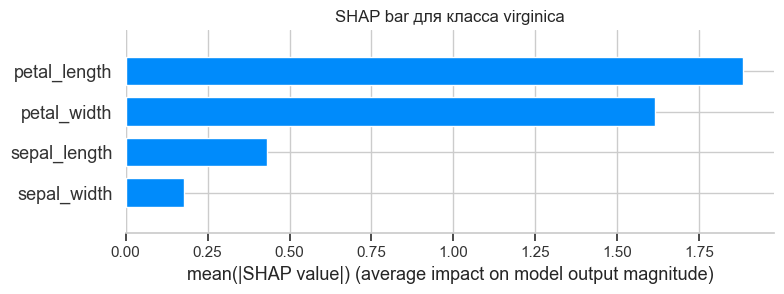

Сохранено: reports\lab3\figures\shap_bar.png


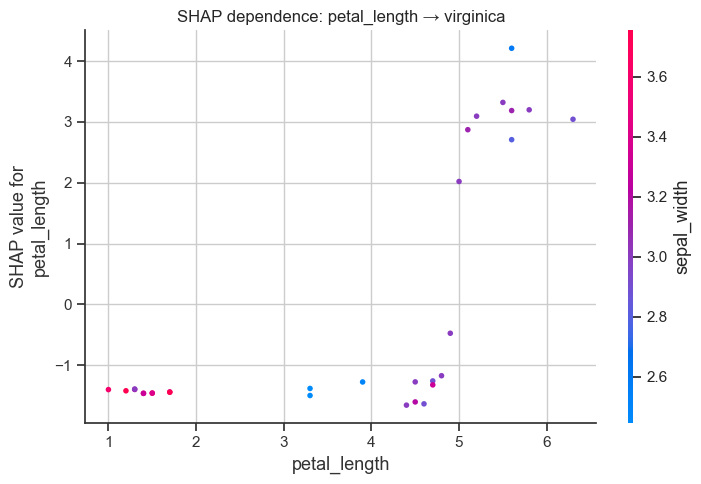

Сохранено: reports\lab3\figures\shap_dependence_1.png


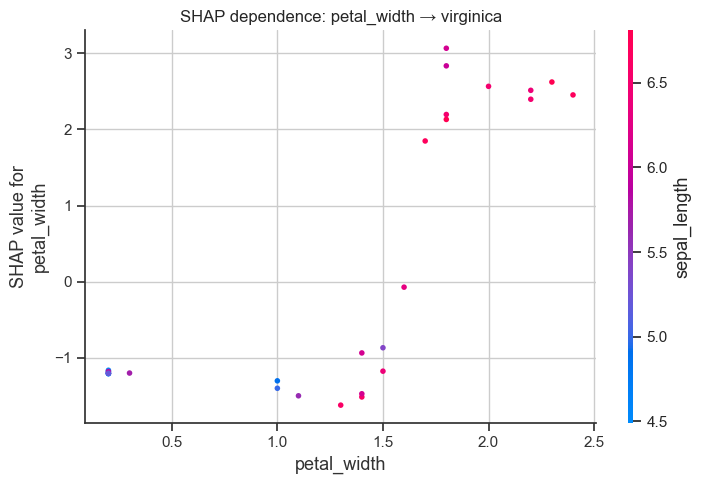

Сохранено: reports\lab3\figures\shap_dependence_2.png


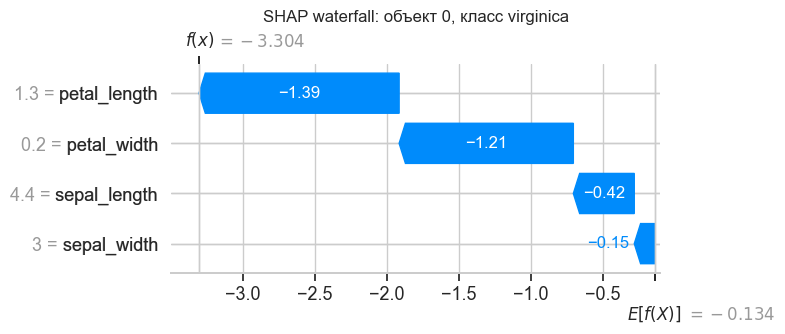

Сохранено: reports\lab3\figures\shap_waterfall_1.png


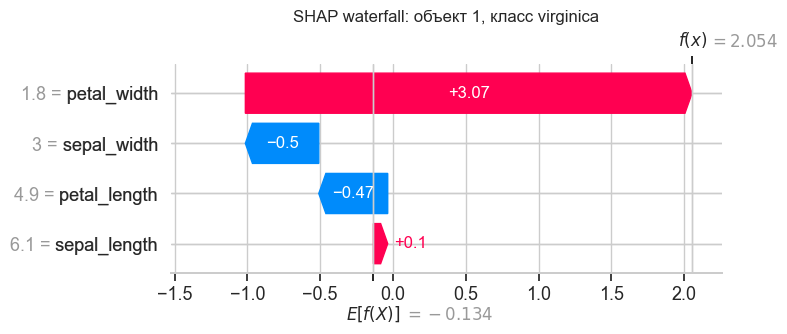

Сохранено: reports\lab3\figures\shap_waterfall_2.png


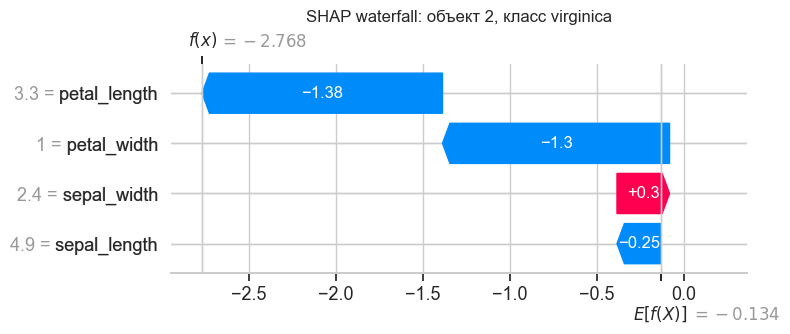

Сохранено: reports\lab3\figures\shap_waterfall_3.png


In [6]:
explainer = shap.TreeExplainer(optimized_model)
shap_explanation = explainer(X_test)
class_index = 2
class_name = iris.target_names[class_index]

if shap_explanation.values.ndim == 3:
    class_values = shap_explanation.values[:, :, class_index]
    if np.ndim(shap_explanation.base_values) == 2:
        class_base = shap_explanation.base_values[:, class_index]
    else:
        class_base = np.repeat(np.asarray(shap_explanation.base_values)[class_index], len(X_test))
else:
    class_values = shap_explanation.values
    class_base = np.asarray(shap_explanation.base_values)

mean_abs_shap = np.abs(class_values).mean(axis=0)
shap_importance = pd.DataFrame({"feature": features, "mean_abs_shap": mean_abs_shap})
shap_importance = shap_importance.sort_values("mean_abs_shap", ascending=False)
shap_importance.to_csv(REPORT_DIR / "shap_feature_importance.csv", index=False)
top_features = shap_importance["feature"].head(2).tolist()
display(shap_importance)

shap.summary_plot(class_values, X_test, feature_names=features, show=False)
plt.title(f"SHAP summary для класса {class_name}")
save_figure("shap_summary.png")

shap.summary_plot(class_values, X_test, feature_names=features, plot_type="bar", show=False)
plt.title(f"SHAP bar для класса {class_name}")
save_figure("shap_bar.png")

for index, feature in enumerate(top_features, start=1):
    shap.dependence_plot(feature, class_values, X_test, feature_names=features, show=False)
    plt.title(f"SHAP dependence: {feature} → {class_name}")
    save_figure(f"shap_dependence_{index}.png")

base_values_array = np.asarray(class_base).reshape(-1)
waterfall_object_indices = [0, 1, 2]
for waterfall_number, object_index in enumerate(waterfall_object_indices, start=1):
    base_value = (base_values_array[object_index]
                  if len(base_values_array) == len(X_test) else base_values_array[0])
    waterfall_explanation = shap.Explanation(
        values=class_values[object_index],
        base_values=float(base_value),
        data=X_test.iloc[object_index].values,
        feature_names=features,
    )
    shap.plots.waterfall(waterfall_explanation, show=False)
    plt.title(f"SHAP waterfall: объект {object_index}, класс {class_name}")
    save_figure(f"shap_waterfall_{waterfall_number}.png")

## 7. Стекинг

По варианту стекинг объединяет LightGBM, RandomForest и SVC. Метамодель —
LogisticRegression; cv=5 и stack_method='predict_proba'.

,model,roc_auc_mean,roc_auc_std,accuracy_mean,f1_macro_mean,fit_time_mean
1,CatBoost optimized,1.000000,0.000000,0.950000,0.949406,0.046680
0,CatBoost default,0.998958,0.002083,0.958333,0.957971,0.597052
2,Stacking,0.998958,0.002083,0.958333,0.957971,1.271868


Финальная модель по CV: CatBoost optimized


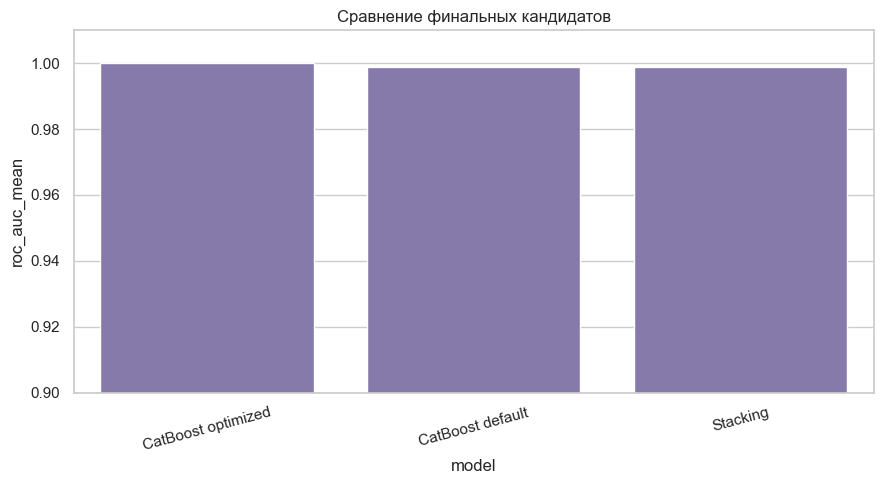

Сохранено: reports\lab3\figures\model_comparison.png


In [7]:
stacking_model = StackingClassifier(
    estimators=[
        ("lightgbm", LGBMClassifier(n_estimators=100, random_state=RANDOM_STATE,
                                    n_jobs=1, verbosity=-1)),
        ("random_forest", RandomForestClassifier(
            n_estimators=250, random_state=RANDOM_STATE, n_jobs=1)),
        ("svc", Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(probability=True, random_state=RANDOM_STATE)),
        ])),
    ],
    final_estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1,
)

comparison_models = {
    f"{best_library} default": baseline_models[best_library],
    f"{best_library} optimized": optimized_model,
    "Stacking": stacking_model,
}
model_rows = []
for name, model in comparison_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    model_rows.append({
        "model": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "accuracy_mean": scores["test_accuracy"].mean(),
        "f1_macro_mean": scores["test_f1"].mean(),
        "fit_time_mean": scores["fit_time"].mean(),
    })

model_comparison = pd.DataFrame(model_rows).sort_values(
    ["roc_auc_mean", "f1_macro_mean"], ascending=False)
model_comparison.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
display(model_comparison)
final_model_name = model_comparison.iloc[0]["model"]
final_model = comparison_models[final_model_name]
final_model.fit(X_train, y_train)
print(f"Финальная модель по CV: {final_model_name}")

plt.figure(figsize=(9, 5))
sns.barplot(data=model_comparison, x="model", y="roc_auc_mean", color="#8172B2")
plt.ylim(0.90, 1.01); plt.xticks(rotation=15); plt.title("Сравнение финальных кандидатов")
save_figure("model_comparison.png")

## 8. Финальная оценка на отложенном test

{
  "variant": 10,
  "dataset": "Iris",
  "best_baseline_library": "CatBoost",
  "optuna_trials": 50,
  "optimized_cv_roc_auc": 1.0,
  "final_model": "CatBoost optimized",
  "test_accuracy": 0.933333,
  "test_precision_macro": 0.933333,
  "test_recall_macro": 0.933333,
  "test_f1_macro": 0.933333,
  "test_roc_auc_macro_ovr": 0.99
}


,precision,recall,f1-score,support
setosa,1.000000,1.000000,1.000000,10.000000
versicolor,0.900000,0.900000,0.900000,10.000000
virginica,0.900000,0.900000,0.900000,10.000000
accuracy,0.933333,0.933333,0.933333,0.933333
macro avg,0.933333,0.933333,0.933333,30.000000
weighted avg,0.933333,0.933333,0.933333,30.000000


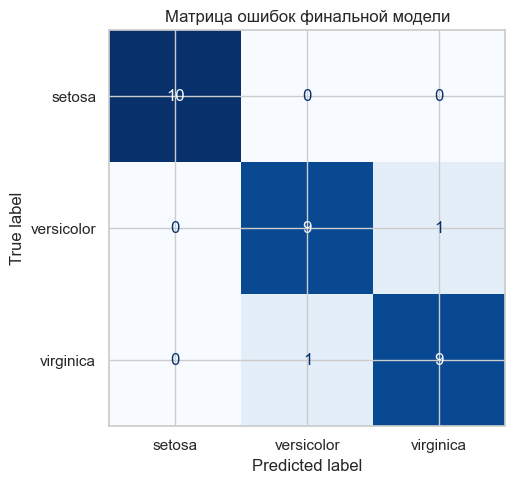

Сохранено: reports\lab3\figures\confusion_matrix.png


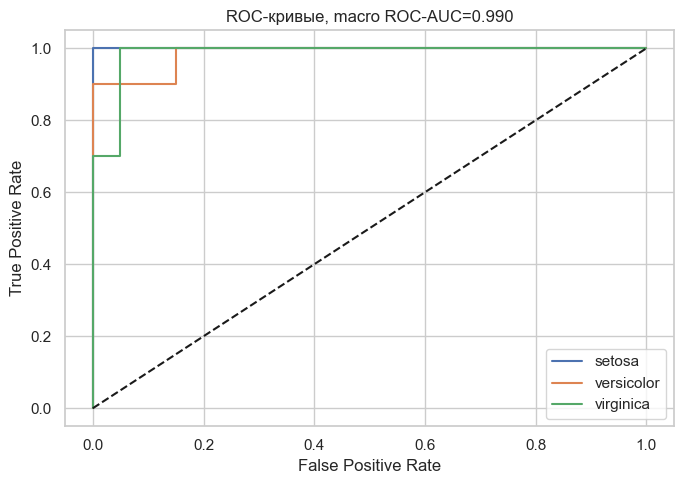

Сохранено: reports\lab3\figures\roc_curves.png


In [8]:
y_pred = np.asarray(final_model.predict(X_test)).reshape(-1)
y_proba = final_model.predict_proba(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro")
recall_macro = recall_score(y_test, y_pred, average="macro")
f1_macro = f1_score(y_test, y_pred, average="macro")
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
cm = confusion_matrix(y_test, y_pred)

metrics = {
    "variant": 10,
    "dataset": "Iris",
    "best_baseline_library": best_library,
    "optuna_trials": 50,
    "optimized_cv_roc_auc": round(float(study.best_value), 6),
    "final_model": final_model_name,
    "test_accuracy": round(float(accuracy), 6),
    "test_precision_macro": round(float(precision_macro), 6),
    "test_recall_macro": round(float(recall_macro), 6),
    "test_f1_macro": round(float(f1_macro), 6),
    "test_roc_auc_macro_ovr": round(float(roc_auc), 6),
}
(REPORT_DIR / "model_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metrics, ensure_ascii=False, indent=2))

class_report = pd.DataFrame(classification_report(
    y_test, y_pred, target_names=iris.target_names, output_dict=True,
    zero_division=0)).T
class_report.to_csv(REPORT_DIR / "classification_report.csv")
display(class_report)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Матрица ошибок финальной модели")
save_figure("confusion_matrix.png")

y_binary = label_binarize(y_test, classes=np.arange(3))
plt.figure(figsize=(7, 5))
for i, name in enumerate(iris.target_names):
    fpr, tpr, _ = roc_curve(y_binary[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.title(f"ROC-кривые, macro ROC-AUC={roc_auc:.3f}")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend()
save_figure("roc_curves.png")

## 9. Сохранение модели, DVC и аналитический отчёт

In [9]:
model_path = MODEL_DIR / "iris_lab3_model.pkl"
with model_path.open("wb") as file:
    cloudpickle.dump(final_model, file)
with model_path.open("rb") as file:
    loaded_model = cloudpickle.load(file)
loaded_predictions = np.asarray(loaded_model.predict(X_test)).reshape(-1)
assert np.array_equal(y_pred, loaded_predictions)

def run_command(command):
    result = subprocess.run(command, cwd=PROJECT_ROOT, capture_output=True,
                            text=True, encoding="utf-8", errors="replace")
    print(f"$ {' '.join(map(str, command))}")
    if result.stdout.strip(): print(result.stdout.strip())
    if result.stderr.strip(): print(result.stderr.strip())
    return result

for artifact in (raw_path, train_path, test_path, model_path):
    result = run_command([sys.executable, "-m", "dvc", "add", str(artifact)])
    if result.returncode != 0:
        raise RuntimeError(f"DVC не смог добавить {artifact}")
dvc_status = run_command([sys.executable, "-m", "dvc", "status"])

best_baseline_row = boosting_results.iloc[0]
final_row = model_comparison.iloc[0]
top_feature_1, top_feature_2 = top_features
n_errors = int((y_pred != y_test).sum())

report_path = REPORT_DIR / "lab3_summary.md"
report_path.write_text(f"""# Отчёт по лабораторной работе №3

## Постановка задачи

Для варианта 10 выполнено сравнение XGBoost, LightGBM и CatBoost на Iris,
оптимизация лучшей библиотеки через 50 trials Optuna, интерпретация SHAP и
сравнение оптимизированного бустинга со стекингом LightGBM + RandomForest + SVC.

## Данные

Iris содержит 150 объектов, четыре числовых признака и три сбалансированных
класса по 50 объектов. Получено {len(X_train)} train и {len(X_test)} test.
Пропусков нет. Балансирование не применялось, поскольку классы представлены
поровну; SMOTE или веса классов здесь не требуются.

## Сравнение бустингов

Лучшая библиотека по пятифолдовой ROC-AUC — **{best_library}** со значением
{best_baseline_row['roc_auc_mean']:.4f} ± {best_baseline_row['roc_auc_std']:.4f}.
При выборе также учитывались F1-macro и время обучения. Полная таблица находится
в `boosting_comparison.csv`. Модельные гиперпараметры baseline оставлены
библиотечными по умолчанию; заданы только seed, потоки и вывод.

## Оптимизация Optuna

Выполнено 50 trials на тренировочной выборке с пятифолдовой CV. Лучший trial
получил ROC-AUC {study.best_value:.4f}. Параметры: `{study.best_params}`.
Тестовая выборка не участвовала в оптимизации. История поиска и важность
параметров сохранены в `optuna_history.png` и `optuna_param_importance.png`.

## Интерпретация SHAP

Для класса virginica наиболее важны **{top_feature_1}** и **{top_feature_2}**.
SHAP-графики показывают не только глобальную важность, но и направление влияния
значений признаков. Summary, bar, два dependence plot и три waterfall для
разных объектов находятся в
`reports/lab3/figures`.

## Стекинг и выбор финальной модели

Сравнены базовый {best_library}, оптимизированный {best_library} и Stacking.
Лучший кандидат по CV — **{final_model_name}**, ROC-AUC
{final_row['roc_auc_mean']:.4f} ± {final_row['roc_auc_std']:.4f}. Именно он был
обучен на полном train и один раз оценён на test.

## Финальная оценка

| Метрика | Значение |
|---|---:|
| Accuracy | {accuracy:.4f} |
| Precision-macro | {precision_macro:.4f} |
| Recall-macro | {recall_macro:.4f} |
| F1-macro | {f1_macro:.4f} |
| ROC-AUC macro OvR | {roc_auc:.4f} |

Количество ошибок: {n_errors} из {len(y_test)} объектов. Матрица ошибок и
ROC-кривые сохранены отдельно.

## Соответствие требованиям

- Сравнены XGBoost, LightGBM и CatBoost на пятифолдовой CV.
- Зафиксированы качество и время обучения.
- Проведено 50 trials Optuna с фиксированным seed.
- Сохранены история оптимизации и важность гиперпараметров.
- Построены обязательные SHAP summary, bar, dependence и три waterfall.
- Создан StackingClassifier из LightGBM, RandomForest и SVC с cv=5.
- Обоснован отказ от методов балансирования.
- Финальная модель оценена на ранее не использованном test.
- Модель, таблицы, изображения и DVC-файлы сохранены в структуре проекта.

## Вывод

Лабораторная демонстрирует полный цикл выбора продвинутой модели: честное
сравнение библиотек, оптимизацию без доступа к test, интерпретацию решений через
SHAP и проверку ансамблирования. Финальная конфигурация выбрана по результатам
кросс-валидации, а итоговые метрики подтверждены на отложенной выборке.
""", encoding="utf-8")

print(f"Модель: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Отчёт: {report_path.relative_to(PROJECT_ROOT)}")
print("Лабораторная работа №3 выполнена успешно.")

$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\raw\iris_lab3.csv
To track the changes with git, run:

	git add 'data\raw\iris_lab3.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab3\train.csv
To track the changes with git, run:

	git add 'data\processed\lab3\train.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\lab3\test.csv
To track the changes with git, run:

	git add 'data\processed\lab3\test.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\models\iris_lab3_model.pkl
To track the changes with git, run:

	git add 'models\iris_lab3_model.pkl.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc status
data\raw\sample_customers.csv.dvc:
	changed outs:
		not in cache:       data\raw\sample_customers.csv
Модель: models\iris_lab3_model.pkl
Отчёт: reports\lab3\lab3_summary.md
Лабораторная работа №3 выполнена успешно.
